# EDA — Phân loại rác thải 5 lớp

Notebook này trình bày khám phá dữ liệu RealWaste + TrashNet sau khi mapping về
5 lớp: cardboard, glass, metal, paper, plastic.

- Dữ liệu đã qua split v1 (70/15/15).
- Test set được mô tả phân bố nhưng **không dùng để chọn mô hình**.
- Số liệu và hình được sinh bởi `scripts/run_eda.py`.


In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "docs" / "EDA" / "tables" / "image_stats.csv").is_file():
        ROOT = candidate
        break
EDA = ROOT / "docs" / "EDA"
if not (EDA / "tables" / "image_stats.csv").is_file():
    raise FileNotFoundError("Chạy `python scripts/run_eda.py` trước.")

summary = json.loads((EDA / "summary.json").read_text(encoding="utf-8"))
raw_counts = pd.read_csv(EDA / "tables" / "raw_label_counts.csv")
class_counts = pd.read_csv(EDA / "tables" / "class_counts.csv")
split_counts = pd.read_csv(EDA / "tables" / "split_counts.csv")
domain = pd.read_csv(EDA / "tables" / "domain_summary.csv")
duplicates = pd.read_csv(EDA / "tables" / "duplicates.csv")
issues = pd.read_csv(EDA / "tables" / "quality_issues.csv")
print("Đã tải xong dữ liệu EDA.")

Đã tải xong dữ liệu EDA.


## 1. Tổng quan dữ liệu

In [2]:
overview = pd.DataFrame(
    {
        "Chỉ số": [
            "Tổng ảnh",
            "Train",
            "Validation",
            "Test",
            "RealWaste",
            "TrashNet",
            "Imbalance ratio",
            "Số group trùng",
            "Số ảnh trùng (dư)",
        ],
        "Giá trị": [
            summary["total"],
            summary["by_split"]["train"],
            summary["by_split"]["val"],
            summary["by_split"]["test"],
            summary["by_dataset"]["realwaste"],
            summary["by_dataset"]["trashnet"],
            round(summary["imbalance_ratio"], 3),
            summary["duplicate_groups"],
            summary["duplicate_images"],
        ],
    }
)
display(overview)
display(Markdown("**Bảng nhãn gốc và lớp bị loại:**"))
display(raw_counts)

,Chỉ số,Giá trị
0,Tổng ảnh,5482.000
1,Train,3833.000
2,Validation,826.000
3,Test,823.000
4,RealWaste,3092.000
5,TrashNet,2390.000
6,Imbalance ratio,1.624
7,Số group trùng,33.000
8,Số ảnh trùng (dư),35.000


**Bảng nhãn gốc và lớp bị loại:**

,dataset,raw_label,count,canonical,used
0,realwaste,Cardboard,461,cardboard,True
1,realwaste,Food Organics,411,NaN,False
2,realwaste,Glass,420,glass,True
3,realwaste,Metal,790,metal,True
4,realwaste,Miscellaneous Trash,495,NaN,False
5,realwaste,Paper,500,paper,True
6,realwaste,Plastic,921,plastic,True
7,realwaste,Textile Trash,318,NaN,False
8,realwaste,Vegetation,436,NaN,False
9,trashnet,cardboard,403,cardboard,True


**Nhận xét:** 5.482 ảnh thuộc 5 lớp; 1.797 ảnh bị loại vì không có lớp tương ứng
nhất quán giữa hai nguồn. Dữ liệu dùng được chiếm khoảng 75% tổng ảnh gốc.

## 2. Phân bố lớp

,label,realwaste,trashnet,total
0,plastic,921,482,1403
1,metal,790,410,1200
2,paper,500,594,1094
3,glass,420,501,921
4,cardboard,461,403,864


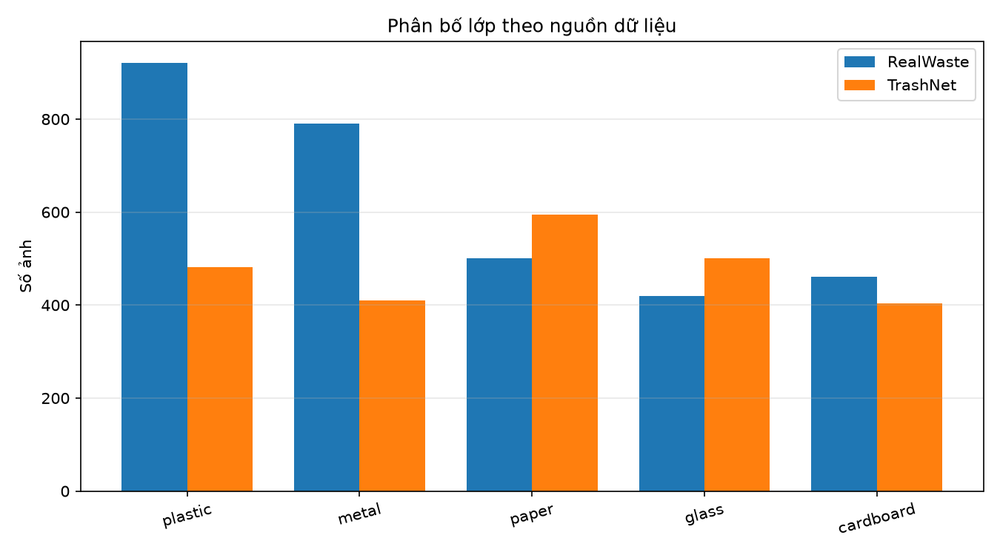

In [3]:
display(class_counts)
display(Image(filename=str(EDA / "figures" / "class_distribution.png")))

**Nhận xét:** plastic nhiều nhất (1.403), cardboard ít nhất (864); tỷ lệ
lớn nhất/nhỏ nhất là 1,62. Mức mất cân bằng vừa phải nhưng đủ để accuracy
không phản ánh đúng lớp thiểu số, nên Macro-F1 là metric chính.

RealWaste đóng góp nhiều metal/plastic; TrashNet đóng góp nhiều glass/paper —
phân phối lớp khác nhau giữa hai nguồn.

## 3. Phân bố split

,split,cardboard,glass,metal,paper,plastic
0,test,130,138,180,164,211
1,train,603,645,839,766,980
2,val,131,138,181,164,212


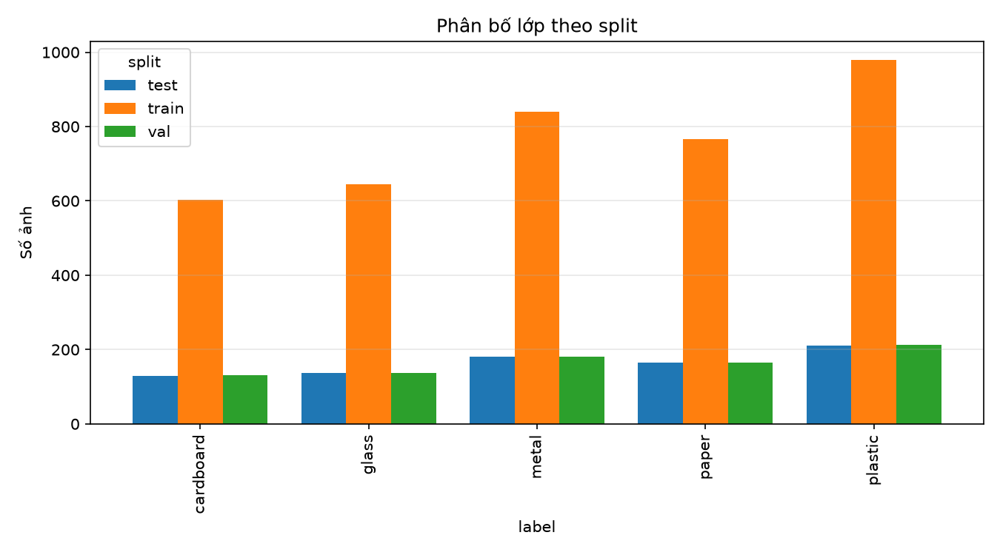

In [4]:
display(split_counts)
display(Image(filename=str(EDA / "figures" / "split_distribution.png")))

**Nhận xét:** tỷ lệ thực tế 69,92% / 15,07% / 15,01%, rất sát 70/15/15.
Mỗi lớp có ít nhất 130 ảnh ở validation và test, đủ để tính Macro-F1 ổn định.
Phân bố lớp giữa các split gần như đồng nhất.

## 4. Ảnh mẫu

### RealWaste

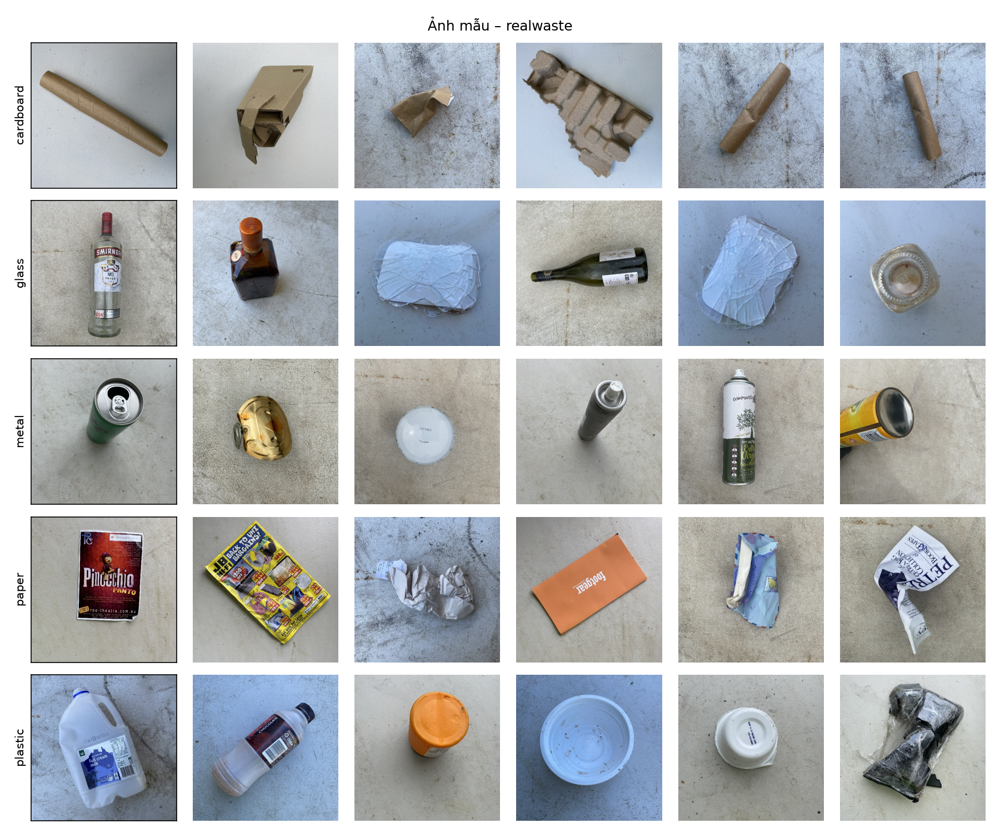

### TrashNet

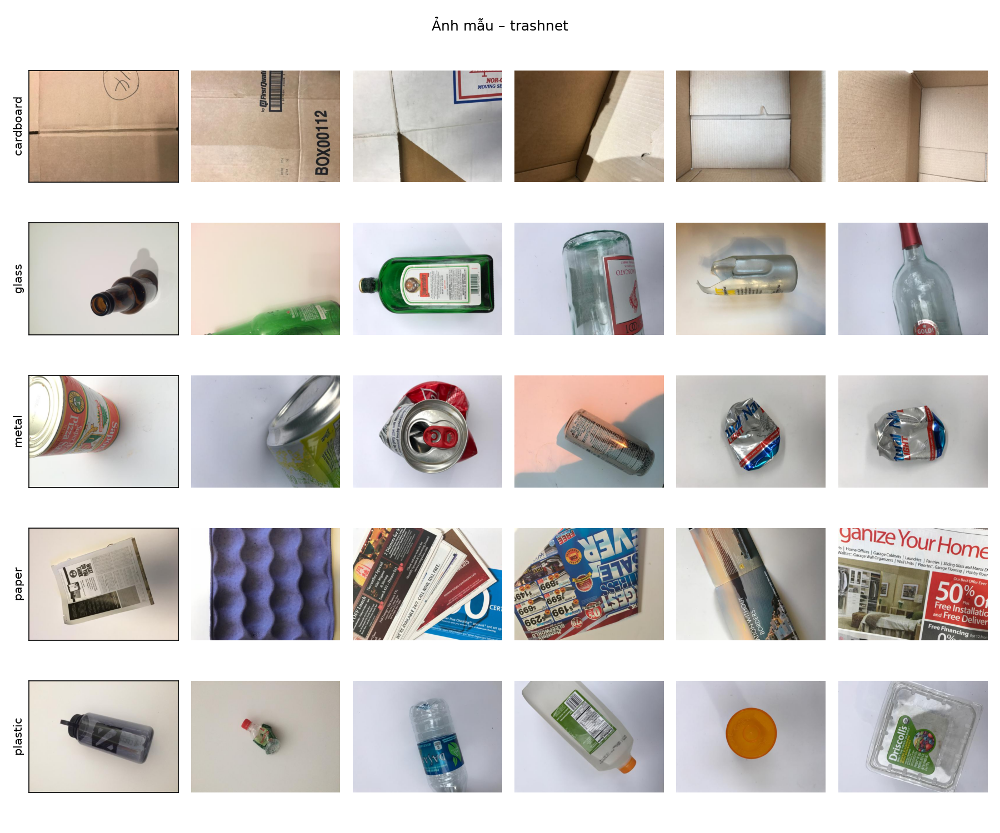

In [5]:
display(Markdown("### RealWaste"))
display(Image(filename=str(EDA / "figures" / "sample_realwaste.png")))
display(Markdown("### TrashNet"))
display(Image(filename=str(EDA / "figures" / "sample_trashnet.png")))

**Nhận xét:** RealWaste có nền thực tế, ánh sáng thay đổi, vật thể có thể bị
che; TrashNet thường đặt vật thể trên nền trắng/đơn giản. Đây là khác biệt domain
chính, ảnh hưởng trực tiếp đến RQ1 (transfer learning) và RQ3 (cross-dataset).

## 5. Thuộc tính ảnh

,dataset,images,width_mean,height_mean,aspect_mean,aspect_std,brightness_mean,brightness_std,blur_mean,blur_median,file_size_kb_mean
0,realwaste,3092,524.0,524.0,1.000000,0.0,155.244938,9.798335,851.130356,720.489319,127.453909
1,trashnet,2390,512.0,384.0,1.333333,0.0,164.495046,20.123493,859.959531,503.643616,16.892996


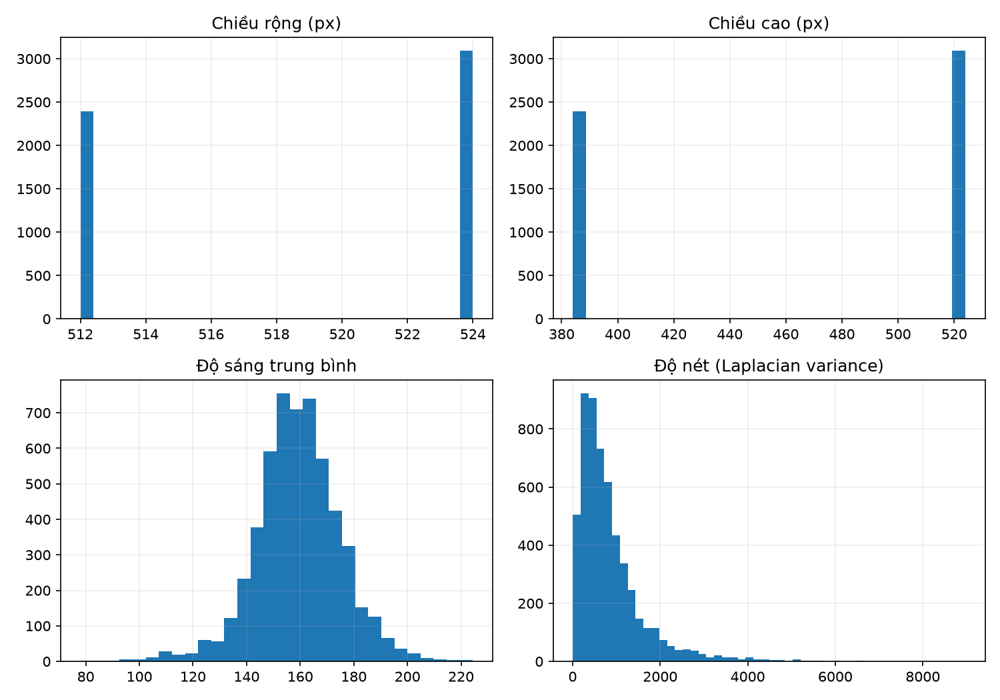

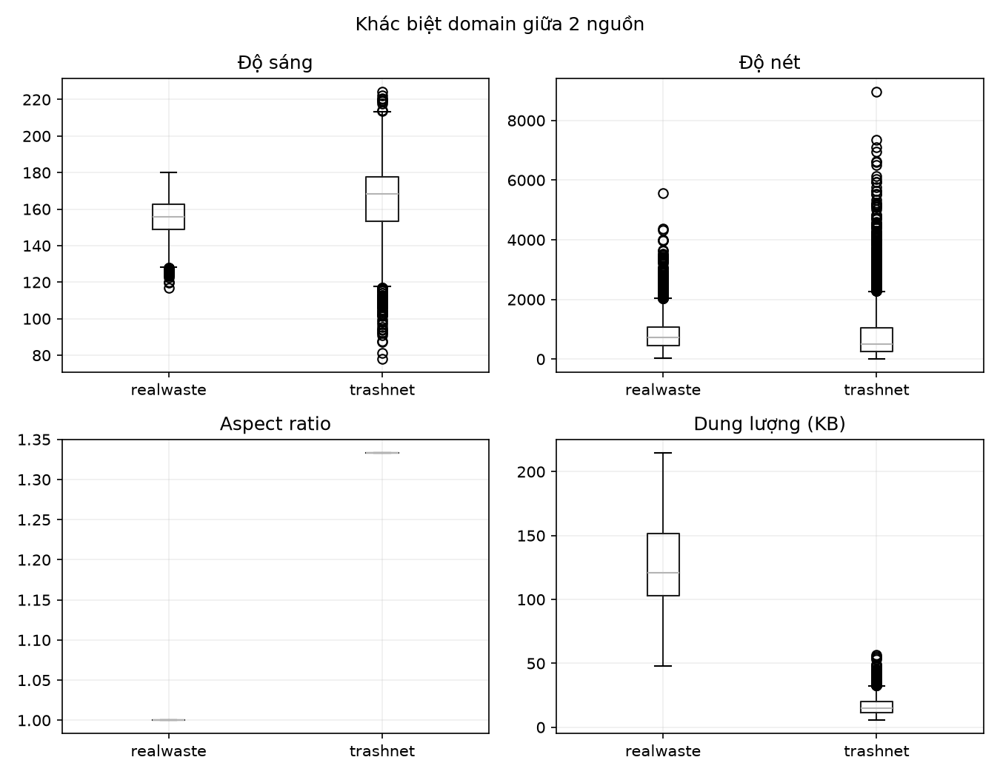

In [6]:
display(domain)
display(Image(filename=str(EDA / "figures" / "image_properties.png")))
display(Image(filename=str(EDA / "figures" / "domain_shift.png")))

**Nhận xét:** RealWaste vuông 524×524, dung lượng trung bình 127,5 KB;
TrashNet 512×384, dung lượng 16,9 KB. Khi resize short side 256 rồi CenterCrop 224,
ảnh TrashNet mất khoảng 1/3 chiều ngang — có thể cắt mất vật thể đặt ngang.
Toàn bộ ảnh là JPEG/RGB; không có ảnh quá nhỏ hoặc quá tối.

## 6. Ảnh trùng và gần trùng

**Các group có hơn 1 ảnh:**

,group_id,images,labels,datasets,splits
0,g001589,3,"metal,plastic",realwaste,train
1,g002299,3,plastic,realwaste,train
2,g000038,2,"cardboard,metal",realwaste,train
3,g001498,2,metal,realwaste,test
4,g002280,2,plastic,realwaste,test
5,g003142,2,cardboard,trashnet,train
6,g003403,2,cardboard,trashnet,test
7,g003505,2,"glass,metal",trashnet,train
8,g003572,2,"glass,plastic",trashnet,test
9,g003808,2,"glass,plastic",trashnet,val


**Group có nhãn xung đột: 7 group / 15 ảnh**

,group_id,images,labels,datasets,splits
0,g001589,3,"metal,plastic",realwaste,train
2,g000038,2,"cardboard,metal",realwaste,train
7,g003505,2,"glass,metal",trashnet,train
8,g003572,2,"glass,plastic",trashnet,test
9,g003808,2,"glass,plastic",trashnet,val
11,g004049,2,"metal,plastic",trashnet,train
13,g004054,2,"metal,plastic",trashnet,train


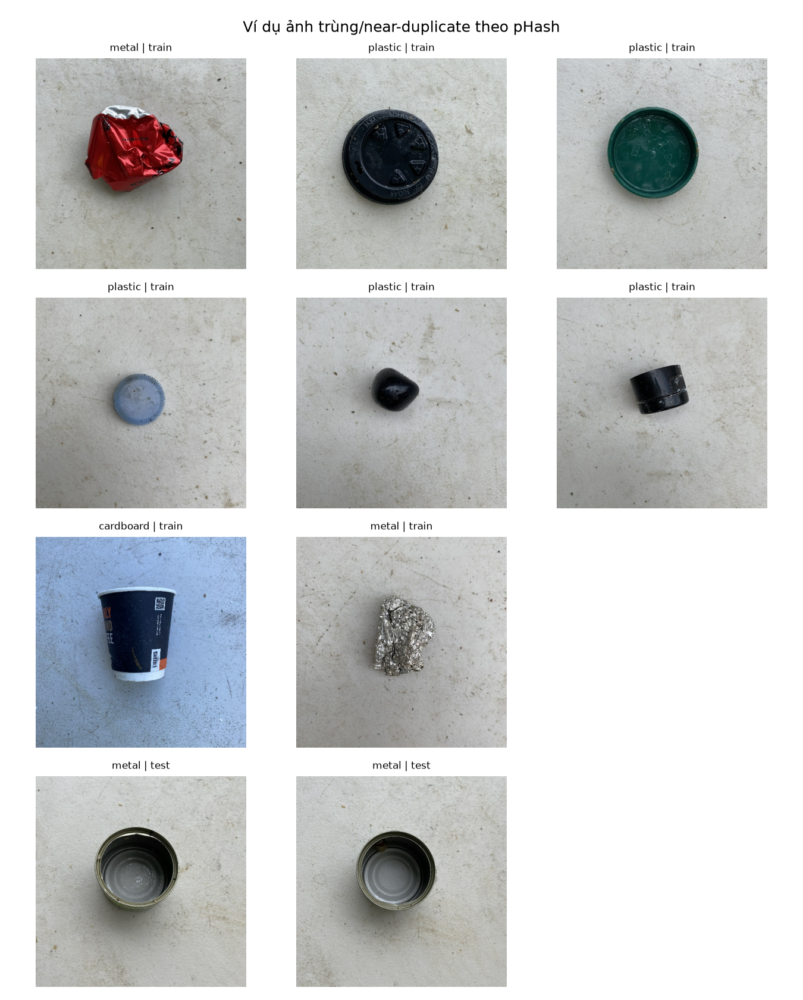

In [7]:
display(Markdown("**Các group có hơn 1 ảnh:**"))
display(duplicates.head(10))
conflicts = duplicates[duplicates["labels"].str.contains(",", na=False)]
display(Markdown(f"**Group có nhãn xung đột: {len(conflicts)} group / {int(conflicts['images'].sum())} ảnh**"))
display(conflicts)
display(Image(filename=str(EDA / "figures" / "duplicates.png")))

**Nhận xét:** 33 group trùng, tương ứng 35 ảnh dư (0,64%). 7 group (15 ảnh)
có nhãn khác nhau giữa các ảnh trùng — nhiễu nhãn tiềm năng. Split v1 đã gom group
để tránh leakage; không có group nào nằm ở hai split.

## 7. Chất lượng ảnh và nhãn

,issue,count
0,blurry,20
1,label_conflicts,7
2,too_bright,4


,issue,group_id,images,labels,datasets,splits,path,dataset,label,raw_label,...,width,height,aspect_ratio,min_side,file_size_kb,mode,format,brightness,contrast,blur
0,label_conflicts,g001589,3.0,"metal,plastic",realwaste,train,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,label_conflicts,g000038,2.0,"cardboard,metal",realwaste,train,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,label_conflicts,g003505,2.0,"glass,metal",trashnet,train,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,label_conflicts,g003572,2.0,"glass,plastic",trashnet,test,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,label_conflicts,g003808,2.0,"glass,plastic",trashnet,val,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,label_conflicts,g004049,2.0,"metal,plastic",trashnet,train,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,label_conflicts,g004054,2.0,"metal,plastic",trashnet,train,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,too_bright,g004115,NaN,NaN,NaN,NaN,raw/trashnet/dataset-resized/metal/metal213.jpg,trashnet,metal,metal,...,512.0,384.0,1.333333,384.0,9.353516,RGB,JPEG,224.415039,45.275375,347.486694
8,too_bright,g004110,NaN,NaN,NaN,NaN,raw/trashnet/dataset-resized/metal/metal209.jpg,trashnet,metal,metal,...,512.0,384.0,1.333333,384.0,10.331055,RGB,JPEG,222.364624,48.370358,405.472778
9,too_bright,g004099,NaN,NaN,NaN,NaN,raw/trashnet/dataset-resized/metal/metal2.jpg,trashnet,metal,metal,...,512.0,384.0,1.333333,384.0,12.058594,RGB,JPEG,220.750916,46.298527,972.881104


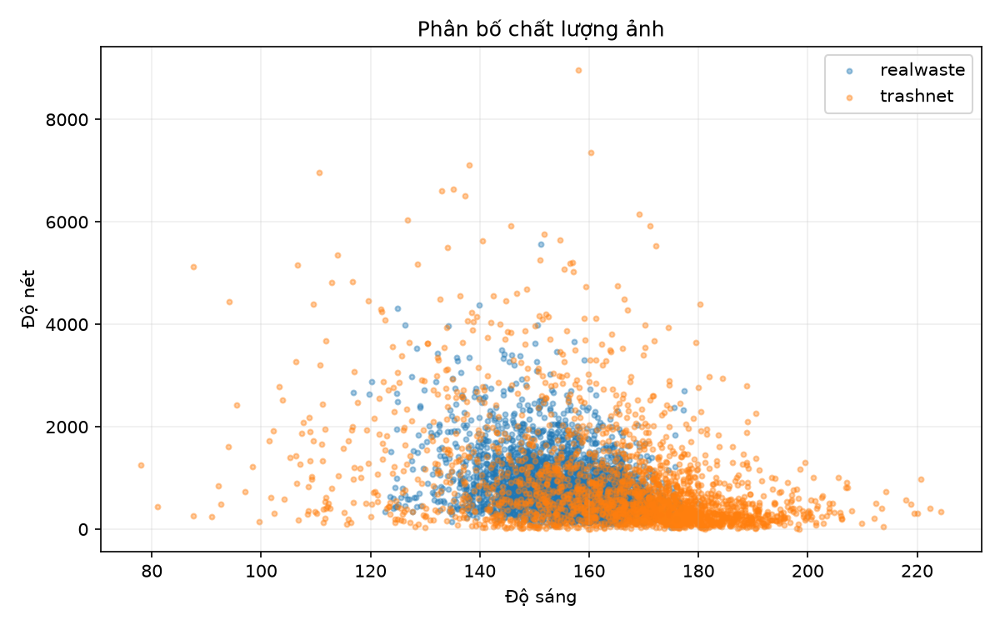

In [8]:
issue_counts = (
    issues.groupby("issue").size().rename("count").reset_index()
    if not issues.empty
    else pd.DataFrame(columns=["issue", "count"])
)
display(issue_counts)
display(issues.head(10))
display(Image(filename=str(EDA / "figures" / "quality_scatter.png")))

**Nhận xét:** không có ảnh hỏng/quá nhỏ/quá tối. 4 ảnh quá sáng và 20 ảnh mờ
(0,36%), chủ yếu ở TrashNet. 7 group xung đột nhãn nên được ghi nhận là hạn chế của
dữ liệu, không tự ý sửa nhãn sau khi đã tạo split.

## 8. Nhận xét tổng hợp

1. **Mất cân bằng vừa phải** → dùng Macro-F1; class weighting là giả thuyết hợp lý cho RQ2.
2. **Khác biệt domain rõ** giữa RealWaste và TrashNet → transfer learning và cross-dataset evaluation có cơ sở.
3. **Ảnh TrashNet 4:3 bị crop** khi dùng 224×224 → cần ghi nhận hạn chế hoặc thử padding/augmentation ở RQ2.
4. **Dữ liệu sạch nhưng có nhiễu nhãn nhỏ** (7 group xung đột) → không nên overfit vào accuracy tuyệt đối.
5. **Split ổn định**, phân bố lớp đồng nhất, test đủ lớn để đánh giá.
6. **Tất cả JPEG/RGB** → không cần xử lý alpha/định dạng đặc biệt.

Chi tiết đầy đủ: `docs/EDA/eda_report.md`.